# 🎯 Lesson 1: K-Means Clustering
### *"Where should we build the milk-cooling plants?"*

**Week 10 · Session 1 of 6 · ⏱ about 2 hours**

---

### 🎯 Learning objectives
By the end of this lesson you will be able to:
1. Explain K-Means **intuitively**, then **mathematically**, then **in code**.
2. Implement K-Means **from scratch** using only NumPy.
3. Explain why **initialisation** matters, and what **k-means++** fixes.
4. Choose the number of clusters *k* with the **elbow method** and the **silhouette score**.
5. Explain, and demonstrate, why you **must scale** your features.
6. Recognise when K-Means is the **wrong tool**.
7. Segment real-looking farmers and name each segment.

### 📋 Prerequisites
Lesson 0, plus: NumPy arrays, pandas DataFrames, and what a Euclidean distance is.

## 1 · The story 📖

A dairy cooperative in the highlands has 300 member farms scattered across the hillsides. The cooperative can afford to build **3 milk-cooling plants**. Farmers must carry fresh milk to the *nearest* plant before it spoils.

**Question:** *Where should the three plants go, so that, overall, farmers travel as little as possible?*

Here is a very human way to solve it:

1. Drop 3 plants anywhere (even randomly).
2. Each farm walks to its **nearest** plant. Now every plant has a "catchment" of farms.
3. Look at each catchment. The plant is clearly in a silly spot if it's off at one edge. **Move the plant to the centre of its farms.**
4. But now some farms are closer to a different plant! **Let every farm re-choose** its nearest plant.
5. Keep alternating *"farms choose nearest plant"* ↔ *"plants move to their farms' centre"* until nothing changes.

Congratulations, you just invented **K-Means** (the real name for step 2–5 is *Lloyd's algorithm*). 

| Story | Machine-learning name |
|---|---|
| A farm | A data point (a row) |
| A cooling plant | A **centroid** (cluster centre) |
| A plant's catchment | A **cluster** |
| Number of plants (3) | **k**: *you* choose it |
| Total travel distance | The **objective** we minimise (*inertia*) |

> 💡 **Intuition.** K-Means is a *summary machine*. It replaces 300 farms with 3 "typical" locations and tells you which typical location each farm belongs to.

## 2 · The algorithm and the math (gently)

Given data points $x_1, \dots, x_n$ and a chosen number of clusters $k$:

| Step | What happens |
|---|---|
| **0. Initialise** | Pick $k$ starting centroids $\mu_1,\dots,\mu_k$ (e.g. random data points) |
| **1. Assign** | Give each point to its nearest centroid: $\;c_i = \arg\min_j \lVert x_i - \mu_j \rVert^2$ |
| **2. Update** | Move each centroid to the **mean** of the points assigned to it: $\;\mu_j = \frac{1}{\lvert C_j\rvert}\sum_{i \in C_j} x_i$ |
| **3. Repeat** | Go back to step 1 until assignments stop changing |

> 📐 **The math, gently.** K-Means tries to minimise the **inertia** (also called *within-cluster sum of squares*, WCSS):
>
> $$ J = \sum_{j=1}^{k} \sum_{x_i \in C_j} \lVert x_i - \mu_j \rVert^2 $$
>
> In words: *"add up the squared distance from every point to the centre of its own cluster."* Smaller = tighter, more compact clusters. 
> Each of the two steps can only **decrease or keep** $J$, so the algorithm is guaranteed to converge. But: and this is crucial: it converges to a **local** minimum, *not necessarily the best one*. Remember this; we'll see it bite us in Section 4.

**Why the mean?** For squared distances, the mean is *exactly* the point that minimises the sum. (Try it: for numbers 1, 2, 9 the mean 4 gives $9+4+25=38$, while the median 2 gives $1+0+49=50$.) That's why it's called K-**Means**.

## 3 · Build it yourself (from scratch!) 🔧

The best way to understand an algorithm is to write it. We'll implement K-Means with only NumPy, then compare with scikit-learn.

First, some toy data where we **know** the right answer: 300 points around 4 centres.

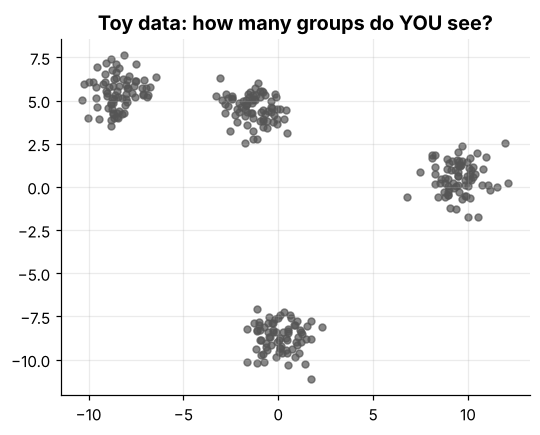

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, adjusted_rand_score
from course_utils import set_style, load, check, plot_clusters_2d, silhouette_plot, profile_clusters
set_style()
RANDOM_STATE = 42

X_toy, y_toy = make_blobs(n_samples=300, centers=4, cluster_std=0.9, random_state=7)
plt.figure(figsize=(5.5, 4.2))
plt.scatter(X_toy[:, 0], X_toy[:, 1], s=20, color="#555", alpha=.7)
plt.title("Toy data: how many groups do YOU see?")
plt.show()

### Step A: the two building blocks

K-Means is just two small functions repeated. Read each slowly.

In [2]:
def assign_clusters(X, centers):
    """Step 1: for every point, find the index of the nearest centre."""
    # X[:, None, :]       has shape (n, 1, d)
    # centers[None, :, :] has shape (1, k, d)
    # subtracting broadcasts to (n, k, d): the difference between every point and every centre
    diffs = X[:, None, :] - centers[None, :, :]
    dists = np.sqrt((diffs ** 2).sum(axis=2))        # shape (n, k): distance to each centre
    return dists.argmin(axis=1)                      # index of the closest centre, per point


def update_centers(X, labels, k, old_centers):
    """Step 2: move each centre to the mean of its points."""
    new_centers = old_centers.copy()
    for j in range(k):
        members = X[labels == j]
        if len(members) > 0:                         # guard: a centre may lose all its points
            new_centers[j] = members.mean(axis=0)
    return new_centers

> 🐞 **Debugging corner.** **Broadcasting confusing you?** Print shapes! Add `print(X[:, None, :].shape, centers[None, :, :].shape)`. NumPy "stretches" the size-1 axes to match, so one subtraction compares *every* point with *every* centre at once: no slow Python loops.

### Step B: put them in a loop

In [3]:
def kmeans_scratch(X, k, n_iter=100, tol=1e-6, seed=0):
    """K-Means from scratch (random-point initialisation).

    Returns labels, centers, inertia, and the history of centres (so we can animate it).
    """
    rng = np.random.default_rng(seed)
    X = np.asarray(X, dtype=float)
    centers = X[rng.choice(len(X), size=k, replace=False)]      # Step 0: pick k random points as centres
    history = [centers.copy()]

    for it in range(n_iter):
        labels = assign_clusters(X, centers)                    # Step 1
        new_centers = update_centers(X, labels, k, centers)     # Step 2
        shift = np.linalg.norm(new_centers - centers)           # how far did the centres move?
        centers = new_centers
        history.append(centers.copy())
        if shift < tol:                                         # Step 3: converged -> stop
            break

    labels = assign_clusters(X, centers)
    inertia = ((X - centers[labels]) ** 2).sum()                # the objective J
    return labels, centers, inertia, history


labels_s, centers_s, inertia_s, history = kmeans_scratch(X_toy, k=4, seed=6)
print(f"Converged after {len(history) - 1} iterations.  Inertia = {inertia_s:.1f}")

Converged after 4 iterations.  Inertia = 462.8


### Watch it think 👀

Let's draw the algorithm at four moments in time. Notice how the black stars (centroids) crawl toward the middle of their groups.

> 🎲 *A small confession:* we chose `seed=6` because it starts from a lucky arrangement. Try `seed=1` or `seed=5` and you'll see the centroids get **stuck** in a bad arrangement. That is not a bug: it's a fundamental property of K-Means, and Section 4 is all about it.

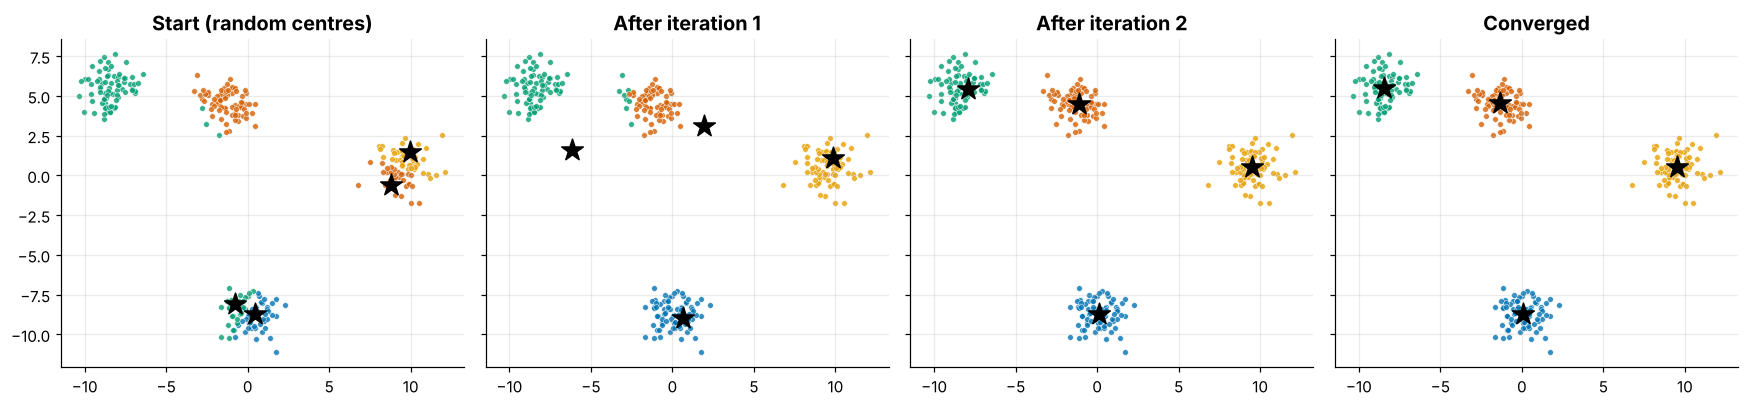

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharex=True, sharey=True)
steps = [0, 1, 2, len(history) - 1]
for ax, t in zip(axes, steps):
    lab = assign_clusters(X_toy, history[t])
    plot_clusters_2d(X_toy, lab, centers=history[t], ax=ax, annotate_centers=False, s=14)
    ax.set_title("Start (random centres)" if t == 0 else ("Converged" if t == steps[-1] else f"After iteration {t}"))
    ax.legend().set_visible(False)
plt.tight_layout(); plt.show()

### Step C: compare with scikit-learn

scikit-learn's `KMeans` does the same job, but with better initialisation, speed, and edge-case handling.

In [5]:
km = KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE).fit(X_toy)
print(f"scikit-learn inertia : {km.inertia_:.1f}")
print(f"our scratch inertia  : {inertia_s:.1f}")
print(f"Do the two agree on who belongs together?  Adjusted Rand Index = {adjusted_rand_score(km.labels_, labels_s):.3f}   (1.0 = identical groupings)")

scikit-learn inertia : 462.8
our scratch inertia  : 462.8
Do the two agree on who belongs together?  Adjusted Rand Index = 1.000   (1.0 = identical groupings)


> 🧠 **Remember.** The **API pattern** is the same for every scikit-learn model: create → `fit` → use. For K-Means:
> `km.labels_` (group of each training point), `km.cluster_centers_` (the centroids), `km.inertia_` (the objective J), `km.predict(new_points)` (assign *new* points to the nearest centroid), and `km.n_iter_`.

## 4 · Initialisation matters: the bad-luck problem 🎲

We said K-Means finds a **local** minimum. Let's *see* that. Below: a dataset with 5 clear groups. We run K-Means from 10 different random starting positions and record the final inertia.

Final inertia from 10 random starts:
[1137, 500, 500, 500, 1137, 1198, 1197, 500, 1197, 1192]


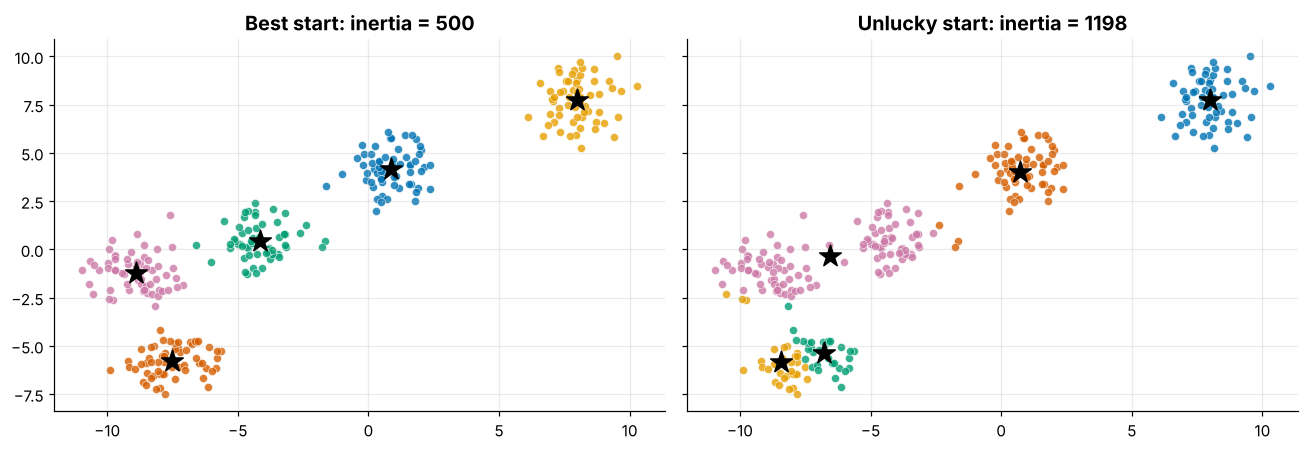

In [6]:
X5, _ = make_blobs(n_samples=300, centers=5, cluster_std=0.9, random_state=3)

results = []
for seed in range(10):
    lab, cen, inertia, _ = kmeans_scratch(X5, k=5, seed=seed)
    results.append((seed, lab, cen, inertia))

print("Final inertia from 10 random starts:")
print([round(r[3]) for r in results])

best = min(results, key=lambda r: r[3]); worst = max(results, key=lambda r: r[3])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharex=True, sharey=True)
plot_clusters_2d(X5, best[1], best[2], ax=axes[0], title=f"Best start: inertia = {best[3]:.0f}", annotate_centers=False)
plot_clusters_2d(X5, worst[1], worst[2], ax=axes[1], title=f"Unlucky start: inertia = {worst[3]:.0f}", annotate_centers=False)
for ax in axes: ax.legend().set_visible(False)
plt.tight_layout(); plt.show()

**What happened?** In the unlucky run, two centroids started inside the same real group, and one real group had to share a centroid with a neighbour. The algorithm got *stuck*: every small move made things locally worse, so it stopped, even though a much better arrangement exists.

### Two professional fixes

**Fix 1: Run it many times** and keep the best result. In scikit-learn that is the `n_init` parameter (we've been using `n_init=10`).

**Fix 2: Start smarter: k-means++**. Instead of picking all starting centres uniformly at random, pick them *spread apart*:
1. Choose the first centre at random from the data.
2. For every point, compute $D(x)$ = distance to the **nearest centre already chosen**.
3. Pick the next centre randomly, but with probability proportional to $D(x)^2$, so far-away points are much more likely.
4. Repeat until you have $k$ centres.

scikit-learn uses k-means++ **by default** (`init="k-means++"`). You'll implement it yourself in Challenge Exercise 6.

In [7]:
# Compare initialisation strategies over 30 single starts each (n_init=1 so luck is fully exposed)
def inertias(init, n=30):
    return [KMeans(5, init=init, n_init=1, random_state=s).fit(X5).inertia_ for s in range(n)]

rand_i, pp_i = inertias("random"), inertias("k-means++")
print(f"random     : worst = {max(rand_i):7.0f}   share of runs stuck in a bad minimum = {np.mean(np.array(rand_i) > 600):.0%}")
print(f"k-means++  : worst = {max(pp_i):7.0f}   share of runs stuck in a bad minimum = {np.mean(np.array(pp_i) > 600):.0%}")

random     : worst =    1198   share of runs stuck in a bad minimum = 47%
k-means++  : worst =     500   share of runs stuck in a bad minimum = 0%


## 5 · Choosing *k*: the million-shilling question 💰

K-Means requires **you** to say how many clusters. There's no oracle. Instead, we use evidence.

### Method 1: The Elbow
Inertia *always* decreases as $k$ grows (at $k=n$ every point is its own cluster: inertia 0!). So we don't look for the minimum: we look for the **elbow**: the point where adding another cluster stops giving a big improvement.

### Method 2: The Silhouette score
For each point $i$:
- $a(i)$ = average distance to the *other points in its own cluster* (how snugly it fits)
- $b(i)$ = average distance to the points in the *nearest other cluster* (how far the next-best home is)

$$ s(i) = \frac{b(i) - a(i)}{\max\{a(i),\, b(i)\}} \in [-1, 1] $$

| Value | Meaning |
|---|---|
| near **+1** | point is deep inside its cluster, far from others 😀 |
| near **0** | point sits on a border between two clusters 😐 |
| **negative** | point is probably in the wrong cluster 😟 |

The **silhouette score** is the average of $s(i)$ over all points. Choose the $k$ with the highest score: as *one* piece of evidence.

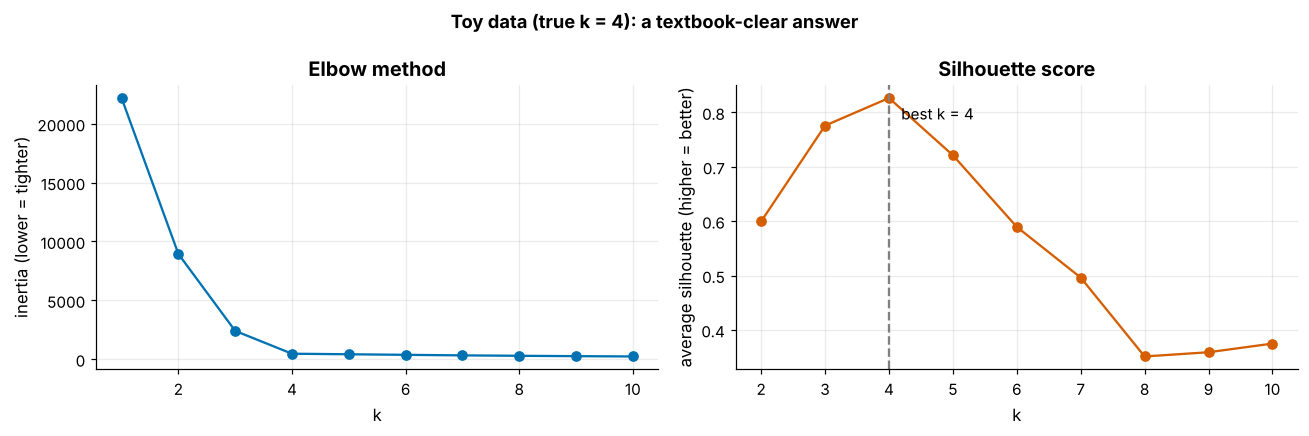

In [8]:
def evaluate_k(X, ks):
    inert, sil = [], []
    for k in ks:
        m = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
        inert.append(m.inertia_)
        sil.append(silhouette_score(X, m.labels_) if k > 1 else np.nan)
    return inert, sil

def plot_k_selection(ks, inert, sil, title=""):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(ks, inert, "o-"); axes[0].set_title("Elbow method"); axes[0].set_xlabel("k"); axes[0].set_ylabel("inertia (lower = tighter)")
    axes[1].plot(ks, sil, "o-", color="#D55E00"); axes[1].set_title("Silhouette score"); axes[1].set_xlabel("k"); axes[1].set_ylabel("average silhouette (higher = better)")
    best_k = ks[int(np.nanargmax(sil))]
    axes[1].axvline(best_k, ls="--", color="grey"); axes[1].annotate(f"best k = {best_k}", (best_k, np.nanmax(sil)), textcoords="offset points", xytext=(8, -14))
    fig.suptitle(title, fontweight="bold"); plt.tight_layout(); plt.show()

ks = list(range(1, 11))
inert, sil = evaluate_k(X_toy, ks)
plot_k_selection(ks, inert, sil, "Toy data (true k = 4): a textbook-clear answer")

On our toy data both methods agree beautifully: a sharp elbow and a silhouette peak at **k = 4**.

**Real data is rarely this kind.** Let's try the retail customers. First, the data-preparation recipe you'll use in *every* clustering project:

1. **Select** the numeric columns that describe the behaviour you care about.
2. **Fix missing values** (here: fill with the median).
3. **Scale** (next section explains why).
4. Cluster.

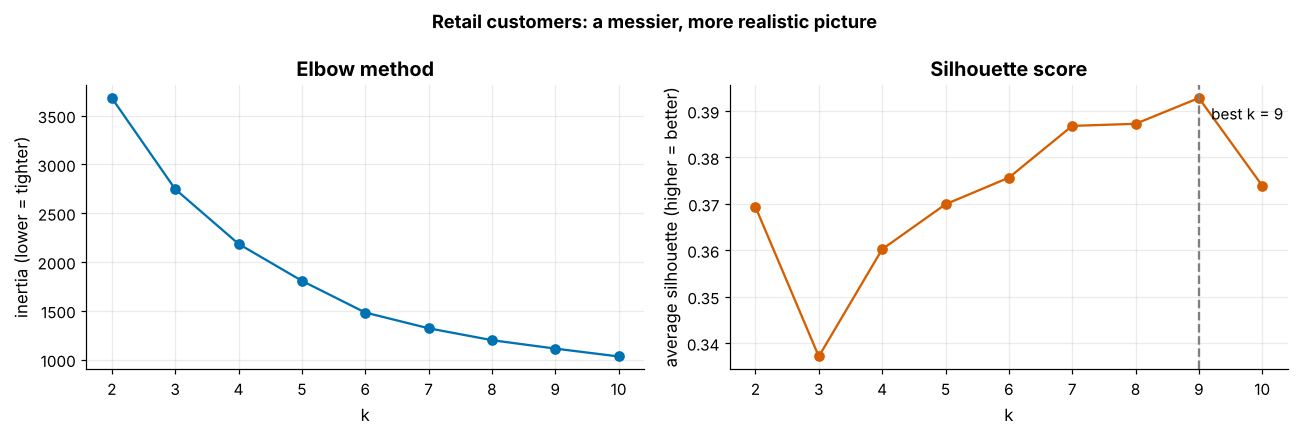

In [9]:
customers = load("retail_customers")
cust_cols = ["age", "annual_income_kes_k", "recency_days", "orders_per_year", "avg_basket_kes", "discount_share", "prefers_online"]

Xc = customers[cust_cols].copy()
Xc = Xc.fillna(Xc.median())                      # step 2: median imputation
Xc_scaled = StandardScaler().fit_transform(Xc)   # step 3: scale

ks = list(range(2, 11))
inert, sil = evaluate_k(Xc_scaled, ks)
plot_k_selection(ks, inert, sil, "Retail customers: a messier, more realistic picture")

> ⚠️ **Watch out.** **There's no sharp elbow, and the silhouette is flat** (roughly 0.34–0.39 across many *k*). This is normal! Real human groups blend into each other. When the metrics don't give a clear winner, **use business sense**: 3 segments might be too coarse to act on; 12 would be too many to run marketing campaigns for. 4–7 is the practical range. The metrics narrow the options; *you* decide.

## 6 · Scaling: the #1 mistake in clustering ⚖️

K-Means uses distance. Distance adds up *differences across columns*. So a column with big numbers has a big say; a column with small numbers is basically ignored.

**Experiment.** In our farmers dataset, `annual_revenue_kes` is in the *millions* and `yield_bags_per_acre` is around 10–40. Let's cluster farmers **without** scaling and see what the algorithm does.

In [10]:
farmers = load("farmers")
cols_scale_demo = ["farm_size_acres", "yield_bags_per_acre", "fertilizer_kg_per_acre", "labour_days_per_acre",
                   "distance_to_market_km", "post_harvest_loss_pct", "annual_revenue_kes"]
Xf = farmers[cols_scale_demo]
Xf = Xf.fillna(Xf.median())

print("Standard deviation of each column (raw):")
print(Xf.std().round(1).to_string())

Standard deviation of each column (raw):
farm_size_acres                34.4
yield_bags_per_acre            10.7
fertilizer_kg_per_acre         35.9
labour_days_per_acre           19.7
distance_to_market_km           6.0
post_harvest_loss_pct           9.3
annual_revenue_kes        1210185.3


In [11]:
raw_labels    = KMeans(4, n_init=10, random_state=RANDOM_STATE).fit_predict(Xf)
scaled_labels = KMeans(4, n_init=10, random_state=RANDOM_STATE).fit_predict(StandardScaler().fit_transform(Xf))
revenue_only  = KMeans(4, n_init=10, random_state=RANDOM_STATE).fit_predict(Xf[["annual_revenue_kes"]])

print("How similar is the 7-feature RAW clustering to clustering on revenue ALONE?")
print(f"   Adjusted Rand Index = {adjusted_rand_score(raw_labels, revenue_only):.2f}   (1.00 = exactly the same!)")
print("And the SCALED 7-feature clustering?")
print(f"   Adjusted Rand Index = {adjusted_rand_score(scaled_labels, revenue_only):.2f}")

How similar is the 7-feature RAW clustering to clustering on revenue ALONE?
   Adjusted Rand Index = 1.00   (1.00 = exactly the same!)
And the SCALED 7-feature clustering?
   Adjusted Rand Index = 0.21


**Wow.** The 7-feature raw clustering is *identical* to clustering on revenue alone (ARI = 1.00). The other six features might as well not exist: their numbers are tiny next to millions of shillings.

### The fix: standardise
`StandardScaler` transforms each column to have **mean 0 and standard deviation 1**:

$$ z = \frac{x - \bar{x}}{\sigma} $$

Now "one unit" means "one standard deviation" in every column, and every feature gets a fair vote.

| Scaler | Formula | Use when |
|---|---|---|
| `StandardScaler` | $(x-\bar x)/\sigma$ | Default choice. Roughly bell-shaped data |
| `MinMaxScaler` | $(x-\min)/(\max-\min)$ | You need a 0–1 range. **Sensitive to outliers** |
| `RobustScaler` | $(x-\text{median})/\text{IQR}$ | Data with outliers |
| `log1p` first | $\log(1+x)$ | Heavily **right-skewed** columns (money, sizes) |

> ⚠️ **Watch out.** Scaling is done on **columns of features**, not rows. And never scale the 0/1 columns *differently* than the rest by accident: binary columns are fine to standardise too, but they'll then represent "a share of the population," which is usually what you want.

## 7 · When K-Means is the wrong tool ⚠️

K-Means quietly assumes that clusters are **round blobs of similar size and spread**. When that fails, it fails silently: it will *always* give you $k$ clusters, whether they make sense or not.

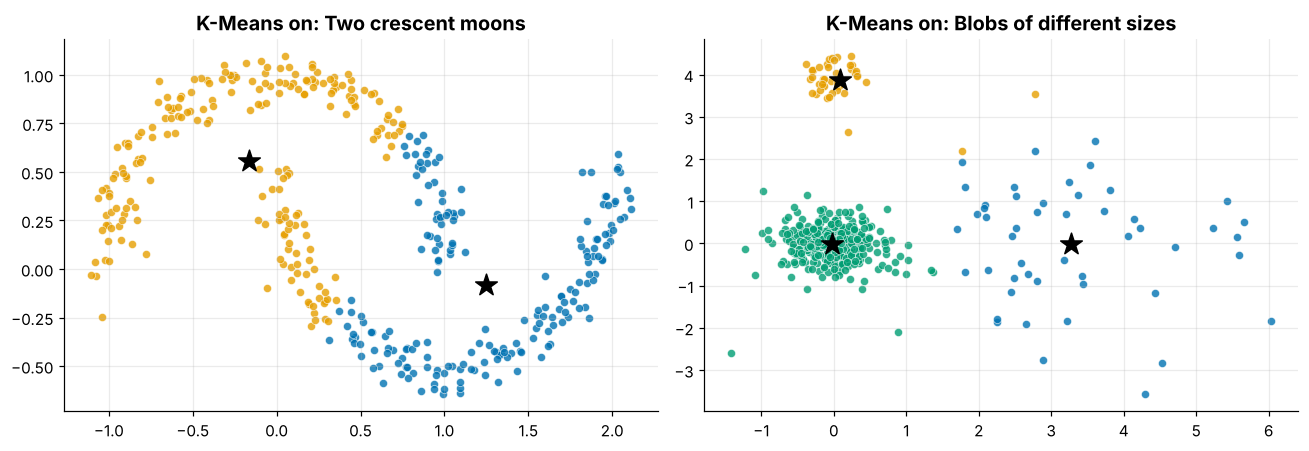

In [12]:
from sklearn.datasets import make_moons

X_moons, _ = make_moons(n_samples=400, noise=0.07, random_state=RANDOM_STATE)
# blobs with very different sizes / spreads
rng = np.random.default_rng(1)
X_unequal = np.vstack([rng.normal([0, 0], 0.4, (300, 2)), rng.normal([3.2, 0], 1.3, (60, 2)), rng.normal([0, 4], 0.25, (40, 2))])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, (data, k, name) in zip(axes, [(X_moons, 2, "Two crescent moons"), (X_unequal, 3, "Blobs of different sizes")]):
    m = KMeans(k, n_init=10, random_state=RANDOM_STATE).fit(data)
    plot_clusters_2d(data, m.labels_, m.cluster_centers_, ax=ax, title=f"K-Means on: {name}", annotate_centers=False)
    ax.legend().set_visible(False)
plt.tight_layout(); plt.show()

Left: K-Means slices the moons with a straight line, cutting *across* both crescents. Right: the big diffuse blob steals points from its neighbour.

**Other K-Means weaknesses to remember:**
- You must **choose k** in advance.
- **Outliers** drag centroids toward them (the mean is sensitive!).
- Only **numeric** features make sense (distance between "Nakuru" and "Meru" is meaningless).
- **Every** point gets assigned; K-Means has no concept of "this one doesn't belong anywhere."

Lessons 2 and 3 (hierarchical clustering and DBSCAN) address these. 🙂

## 8 · Worked example 🌾: Segmenting farmers, start to finish

This is the workflow you'll repeat in the projects. We'll go slowly and explain every decision.

**The business question:** *A county agriculture office has 700 registered farmers and a limited budget. Which natural types of farmer exist, so that training programmes can be tailored?*

### Step 1: Choose features that describe *production patterns*
We pick columns about **how** the farm operates: not IDs, not county names, and **not revenue** (revenue is largely a *consequence* of size × yield; including it would double-count).

In [13]:
prod_cols = ["farm_size_acres", "yield_bags_per_acre", "fertilizer_kg_per_acre", "irrigated",
             "labour_days_per_acre", "improved_seed", "coop_member", "distance_to_market_km", "post_harvest_loss_pct"]
df = farmers.copy()
print("Missing values per feature:")
print(df[prod_cols].isna().sum()[lambda s: s > 0].to_string())

Missing values per feature:
fertilizer_kg_per_acre    15
distance_to_market_km      6
post_harvest_loss_pct     10


### Step 2: Clean: impute and tame the outliers
- **Missing** values → fill with the **median** (robust to outliers).
- `farm_size_acres` is hugely **right-skewed** (a few giant farms). Take `log1p` so that going from 1→2 acres matters about as much as 20→40.

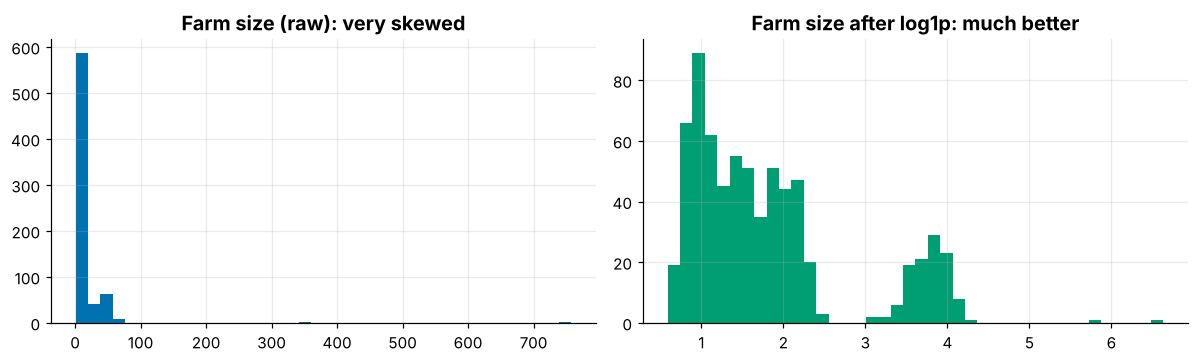

In [14]:
Xf = df[prod_cols].copy()
Xf = Xf.fillna(Xf.median())
Xf["farm_size_acres"] = np.log1p(Xf["farm_size_acres"])      # tame the skew

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].hist(df["farm_size_acres"].dropna(), bins=40, color="#0072B2"); axes[0].set_title("Farm size (raw): very skewed")
axes[1].hist(Xf["farm_size_acres"], bins=40, color="#009E73");       axes[1].set_title("Farm size after log1p: much better")
plt.tight_layout(); plt.show()

### Step 3: Scale, then pick *k*

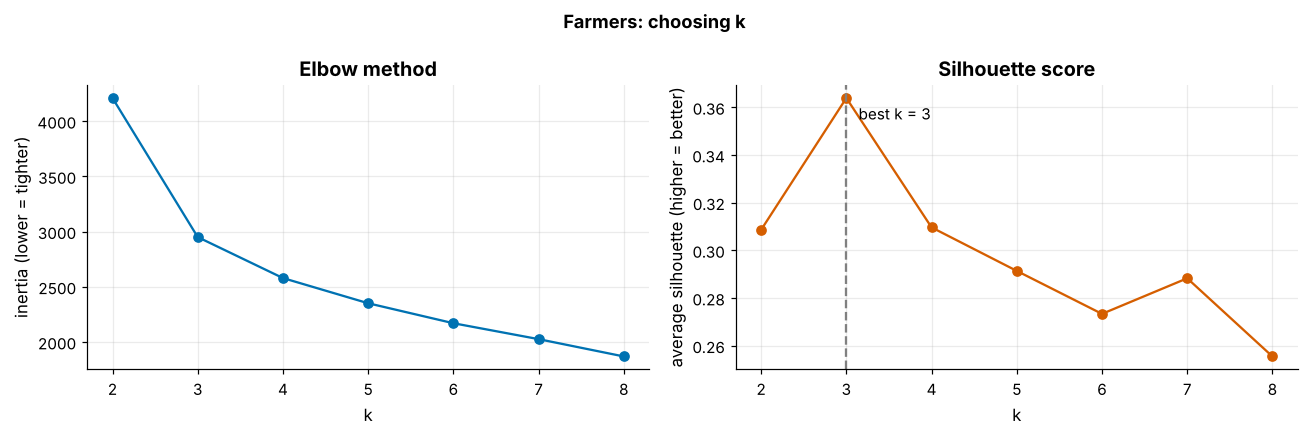

In [15]:
Xf_scaled = StandardScaler().fit_transform(Xf)
ks = list(range(2, 9))
inert, sil = evaluate_k(Xf_scaled, ks)
plot_k_selection(ks, inert, sil, "Farmers: choosing k")

The silhouette likes **k = 3**; the elbow bends around **3–4**. Let's look at both with silhouette plots: a more detailed view that shows *every* farmer's fit.

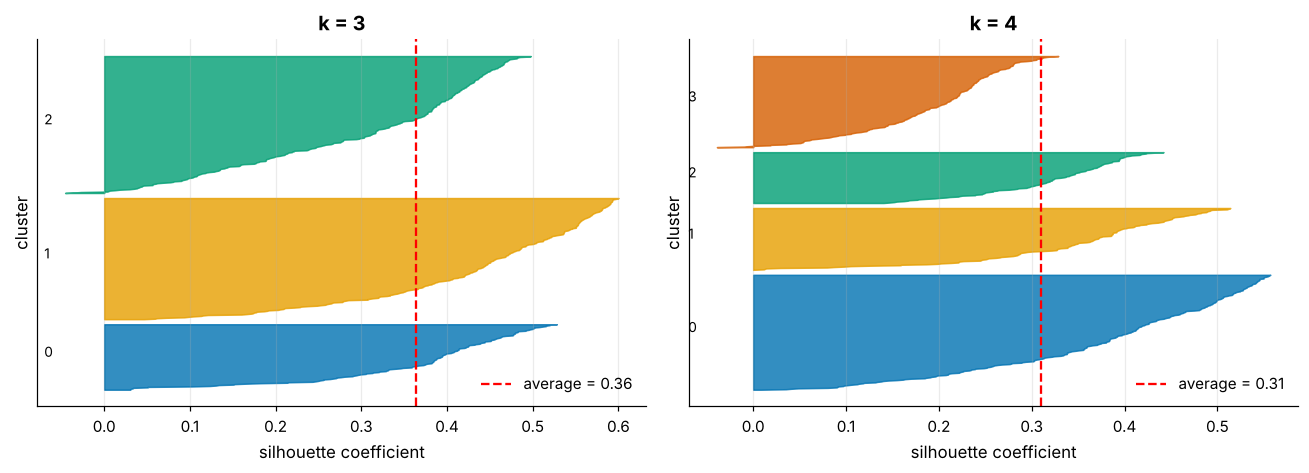

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for ax, k in zip(axes, [3, 4]):
    lab = KMeans(k, n_init=10, random_state=RANDOM_STATE).fit_predict(Xf_scaled)
    silhouette_plot(Xf_scaled, lab, ax=ax, title=f"k = {k}")
plt.tight_layout(); plt.show()

Both are decent. With **k = 4**, every cluster's silhouette extends comfortably past zero. From an extension-service viewpoint, 4 types gives richer, more actionable advice than 3, so we proceed with **k = 4**. *(This is a judgement call: we're using metrics as evidence, not as a dictator.)*

### Step 4: Fit and **profile**
The numbers 0, 1, 2, 3 mean nothing yet. The key step is **profiling**: what's the *average farmer* in each cluster like? We compute the mean of each (original, un-logged) feature per cluster.

In [17]:
km_f = KMeans(4, n_init=10, random_state=RANDOM_STATE).fit(Xf_scaled)
df["cluster"] = km_f.labels_

profile = profile_clusters(df.fillna(df.median(numeric_only=True)), km_f.labels_, prod_cols)
profile

,size,share_%,farm_size_acres,yield_bags_per_acre,fertilizer_kg_per_acre,irrigated,labour_days_per_acre,improved_seed,coop_member,distance_to_market_km,post_harvest_loss_pct
cluster,,,,,,,,,,,
0,252,36.0,1.87,11.78,13.99,0.03,37.56,0.27,0.14,13.84,27.41
1,136,19.4,3.36,37.97,91.35,0.92,59.25,0.89,0.65,6.41,13.74
2,112,16.0,52.31,25.58,69.07,0.08,5.83,0.93,0.59,7.95,9.25
3,200,28.6,6.28,20.46,42.73,0.12,23.46,0.69,0.60,6.26,10.76


### Step 5: Name the clusters (the creative part!)
Read each row of the profile as a *person*:

| Cluster | Reading the numbers | A fitting name |
|---|---|---|
| ? | Tiny plots, low yield, little fertiliser, lots of labour, high losses, almost no irrigation | **Subsistence smallholders** |
| ? | Very large farms, few labour days per acre (mechanised), improved seed | **Commercial grain farmers** |
| ? | Small plots with *very* high yield, heavy fertiliser, **irrigated**, labour-intensive | **Intensive horticulture** |
| ? | Mid-sized, high co-op membership, close to market, low losses | **Dairy / mixed co-op farmers** |

*(Your cluster numbers may differ; matching the right row to the right name is your job. Check the table above!)*

### Step 6: 🔓 The reveal
In this *synthetic* dataset we secretly know the true farmer types. In real life you never could, but since this is a classroom, let's peek **once** to see how we did.

In [18]:
truth = load("farmers_truth")
ct = pd.crosstab(truth["true_segment"], df["cluster"])
print(f"Adjusted Rand Index vs the hidden truth: {adjusted_rand_score(truth['true_segment'], df['cluster']):.2f}\n")
ct

Adjusted Rand Index vs the hidden truth: 0.82



cluster,0,1,2,3
true_segment,,,,
Commercial Grain Farmer,0,0,112,0
Dairy-Mixed Farmer,0,0,0,126
Emerging Market-Oriented,16,2,0,66
Intensive Horticulture,0,134,0,6
Subsistence Smallholder,236,0,0,2


Each hidden farmer type lands mostly in one or two clusters. K-Means had **no labels**, yet it rediscovered the structure. Notice the one place it struggles: the *emerging market-oriented* farmers are a "middle" group that overlaps with others. That's genuinely ambiguous in the data, not a bug.

> 🌾 **Agricultural lens.** The real value isn't the cluster numbers; it's what you *do* with them. Subsistence smallholders → input credit and training on improved seed. Horticulture → cold-chain and market linkage. Commercial grain → storage and price-risk tools. **Different groups, different programmes.**

## 9 · 🧩 Your turn: practice problems

The exercises build from "do it by hand" to "design it yourself". Do them in order. Open hints *one at a time*: the struggle is where the learning happens!

### 🧩 Exercise 1: The assignment step, by hand
**Difficulty:** ⭐  |  **Time:** ~5 min

Here are 5 points and 2 centroids:

```python
pts     = np.array([[1, 1], [2, 1], [8, 8], [9, 8], [5, 5]])
centers = np.array([[1.5, 1.0], [8.5, 8.0]])
```

Using NumPy only (no scikit-learn), compute:
- `dist`: a 5×2 matrix with the Euclidean distance from every point to every centre
- `assign`: an array with the index (0 or 1) of the nearest centre for each point

<details><summary>💡 Hint 1</summary>

Reuse the broadcasting trick: `pts[:, None, :] - centers[None, :, :]` has shape (5, 2, 2).

</details>
<details><summary>💡 Hint 2</summary>

Square it, `.sum(axis=2)`, then `np.sqrt` to get the (5, 2) distance matrix.

</details>
<details><summary>💡 Hint 3</summary>

`dist.argmin(axis=1)` gives, for each row, the column index of the smallest distance.

</details>

In [19]:
pts     = np.array([[1, 1], [2, 1], [8, 8], [9, 8], [5, 5]])
centers = np.array([[1.5, 1.0], [8.5, 8.0]])

# YOUR CODE HERE

In [ ]:
# ✔ Self-check (run me after you've written your answer)
check('dist has shape (5, 2)', lambda: dist.shape == (5, 2))
check('assign is [0, 0, 1, 1, 1]  (the point (5,5) is slightly closer to the second centre!)', lambda: list(assign) == [0, 0, 1, 1, 1])

### 🧩 Exercise 2: The update step and the inertia, by hand
**Difficulty:** ⭐  |  **Time:** ~5 min

Continuing with the same `pts` and `assign` from Exercise 1:

- `new_centers`: move each centre to the **mean** of the points assigned to it (a 2×2 array)
- `inertia`: the sum of squared distances from every point to **its (new) centre**

<details><summary>💡 Hint 1</summary>

For cluster 0: `pts[assign == 0].mean(axis=0)`. Do it for cluster 1 too and stack them with `np.array([...])`.

</details>
<details><summary>💡 Hint 2</summary>

Inertia = `((pts - new_centers[assign]) ** 2).sum()`. Indexing `new_centers[assign]` gives each point's own centre.

</details>

In [21]:
# YOUR CODE HERE

In [ ]:
# ✔ Self-check (run me after you've written your answer)
check('new_centers is [[1.5, 1.0], [7.333, 7.0]]', lambda: np.allclose(new_centers, [[1.5, 1.0], [22/3, 7.0]]))
check('inertia is about 15.17', lambda: abs(inertia - 15.1667) < 0.01)

### 🧩 Exercise 3: Elbow and silhouette on the retail customers
**Difficulty:** ⭐⭐  |  **Time:** ~10 min

Using the already-prepared `Xc_scaled` (retail customers, scaled), for each `k` from **2 to 8**:

- fit `KMeans(n_clusters=k, n_init=10, random_state=42)`
- record the inertia in a list `inertias`
- record the silhouette score in a list `silhouettes`

Then set `best_k` to the `k` with the highest silhouette score.

<details><summary>💡 Hint 1</summary>

Write a `for k in range(2, 9):` loop and `.append()` to two empty lists.

</details>
<details><summary>💡 Hint 2</summary>

`model = KMeans(...).fit(Xc_scaled)` then `model.inertia_` and `silhouette_score(Xc_scaled, model.labels_)`.

</details>
<details><summary>💡 Hint 3</summary>

`best_k = range(2, 9)[int(np.argmax(silhouettes))]`: `argmax` returns a *position*, not the k value itself!

</details>

In [23]:
inertias, silhouettes = [], []
# YOUR CODE HERE

In [ ]:
# ✔ Self-check (run me after you've written your answer)
check('7 values recorded for each', lambda: len(inertias) == 7 and len(silhouettes) == 7)
check('inertia always decreases as k grows', lambda: all(a > b for a, b in zip(inertias, inertias[1:])))
check('best_k is between 2 and 8', lambda: best_k in range(2, 9))
check('best_k really has the max silhouette', lambda: silhouettes[best_k - 2] == max(silhouettes))

### 🧩 Exercise 4: Markets: what does silhouette say: and what does *domain knowledge* say?
**Difficulty:** ⭐⭐  |  **Time:** ~10 min

Cluster the **markets** dataset on these 10 features (scale them first!):

```python
market_cols = ["avg_daily_traders", "avg_daily_volume_tonnes", "price_volatility", "distance_to_city_km",
               "road_quality_1_5", "has_cold_storage", "perishable_share", "n_commodities",
               "mobile_payment_share", "market_days_per_week"]
```

1. For k = 2…6, compute silhouette scores into a dict `sil_by_k` (`{2: score, 3: score, ...}`).
2. Set `best_k_markets` to the k with the best silhouette.
3. Set `chosen_k_markets` to the k you'd *actually* recommend, and explain in a comment why. (Hint: a trade ministry thinks in terms of *urban hubs, regional aggregators, rural periodic markets, and border gateways*.)

<details><summary>💡 Hint 1</summary>

Load with `markets = load('markets')`, then `StandardScaler().fit_transform(markets[market_cols])`.

</details>
<details><summary>💡 Hint 2</summary>

Use a dict comprehension: `{k: silhouette_score(Xm, KMeans(k, n_init=10, random_state=42).fit_predict(Xm)) for k in range(2, 7)}`.

</details>
<details><summary>💡 Hint 3</summary>

`max(sil_by_k, key=sil_by_k.get)` returns the key with the largest value.

</details>
<details><summary>💡 Hint 4</summary>

There's no single right `chosen_k_markets`: anywhere from 3 to 5 is defensible. The point is to *justify* it: silhouette is only one lens.

</details>

In [25]:
market_cols = ["avg_daily_traders", "avg_daily_volume_tonnes", "price_volatility", "distance_to_city_km",
               "road_quality_1_5", "has_cold_storage", "perishable_share", "n_commodities",
               "mobile_payment_share", "market_days_per_week"]
markets = load("markets")
# YOUR CODE HERE

In [ ]:
# ✔ Self-check (run me after you've written your answer)
check('sil_by_k has keys 2..6', lambda: sorted(sil_by_k) == [2, 3, 4, 5, 6])
check('best_k_markets is the argmax', lambda: sil_by_k[best_k_markets] == max(sil_by_k.values()))
check('chosen_k_markets is between 2 and 6', lambda: chosen_k_markets in range(2, 7))

### 🧩 Exercise 5: Prove that scaling matters (yourself)
**Difficulty:** ⭐⭐  |  **Time:** ~8 min

Reproduce the scaling experiment with the **markets** data, using these three columns only:
`avg_daily_traders` (hundreds), `avg_daily_volume_tonnes` (hundreds), `price_volatility` (≈ 0.1–0.5).

1. Fit K-Means (k = 3) on the **raw** columns → `raw_lab`.
2. Fit K-Means (k = 3) on the **standardised** columns → `std_lab`.
3. Compute `ari_raw_std`: the Adjusted Rand Index between the two labelings.
4. Compute `vol_std_raw` and `volat_std_raw`: the standard deviations of `avg_daily_volume_tonnes` and `price_volatility` in the raw data.

Then think: *in the raw clustering, did `price_volatility` have any real influence?*

<details><summary>💡 Hint 1</summary>

`cols3 = ['avg_daily_traders', 'avg_daily_volume_tonnes', 'price_volatility']`; `Xr = markets[cols3]`.

</details>
<details><summary>💡 Hint 2</summary>

`adjusted_rand_score(raw_lab, std_lab)` compares two labelings, regardless of what the cluster numbers are called.

</details>
<details><summary>💡 Hint 3</summary>

Compare `markets['price_volatility'].std()` (≈0.1) with `markets['avg_daily_traders'].std()` (≈ hundreds). A column whose spread is 1000× smaller contributes about 1000²× less to squared distances.

</details>

In [27]:
markets = load("markets")
cols3 = ["avg_daily_traders", "avg_daily_volume_tonnes", "price_volatility"]
# YOUR CODE HERE

In [ ]:
# ✔ Self-check (run me after you've written your answer)
check('raw_lab and std_lab have 103 entries', lambda: len(raw_lab) == 103 and len(std_lab) == 103)
check('ARI is a valid number <= 1', lambda: ari_raw_std <= 1.0)
check("volatility's std is tiny compared with volume's", lambda: volat_std_raw < 0.01 * vol_std_raw)

### 🧩 Exercise 6: 🏆 Challenge: implement k-means++ initialisation
**Difficulty:** ⭐⭐⭐  |  **Time:** ~20 min

Write a function `kmeanspp_init(X, k, seed=0)` that returns a `(k, d)` array of starting centres chosen with the **k-means++** rule:

1. Pick the first centre uniformly at random from the rows of `X`.
2. For each remaining centre: compute, for every point, the **squared distance to its nearest already-chosen centre**; choose the next centre randomly with probability **proportional** to those squared distances.

Then test it on `X5` (the 5-blob data): `centers0 = kmeanspp_init(X5, 5)`.

<details><summary>💡 Hint 1</summary>

Use `rng = np.random.default_rng(seed)`; the first centre is `X[rng.integers(len(X))]`.

</details>
<details><summary>💡 Hint 2</summary>

Inside a loop, keep a list `centers`. For each point, `d2 = ((X[:, None, :] - np.array(centers)[None, :, :]) ** 2).sum(axis=2).min(axis=1)`.

</details>
<details><summary>💡 Hint 3</summary>

Turn into probabilities: `p = d2 / d2.sum()`; then `idx = rng.choice(len(X), p=p)` and append `X[idx]`.

</details>
<details><summary>💡 Hint 4</summary>

Edge case: points that are already chosen have `d2 = 0`, so they can never be chosen twice. That's the beauty of the rule!

</details>

In [29]:
def kmeanspp_init(X, k, seed=0):
    # YOUR CODE HERE
    pass

# centers0 = kmeanspp_init(X5, 5)

In [ ]:
# ✔ Self-check (run me after you've written your answer)
check('returns a (5, 2) array', lambda: kmeanspp_init(X5, 5).shape == (5, 2))
check('all 5 centres are distinct rows of X5', lambda: len({tuple(c) for c in kmeanspp_init(X5, 5)}) == 5 and all(any(np.allclose(c, r) for r in X5) for c in kmeanspp_init(X5, 5)))
check('k-means++ starts reach the good solution (inertia < 600) in at least 7 of 10 runs', lambda: np.mean([KMeans(5, init=kmeanspp_init(X5, 5, s), n_init=1).fit(X5).inertia_ < 600 for s in range(10)]) >= 0.7)

### 🎯 Check your understanding
*Try to answer each question out loud or on paper before you peek.*

**Q1.** Why does K-Means update each centroid to the **mean** of its points (rather than, say, the median)?

<details><summary>Show answer</summary>

Because K-Means minimises the sum of **squared** Euclidean distances, and the mean is exactly the point that minimises that quantity. (The median-based cousin that minimises absolute distances is called K-Medians.)

</details>

**Q2.** Inertia always goes down when you increase *k*. So why can't we just pick the *k* with the lowest inertia?

<details><summary>Show answer</summary>

At $k = n$ every point is its own cluster and inertia is zero: a perfect but useless 'clustering'. We look for the **elbow** (diminishing returns) or use scores like **silhouette** that penalise clusters that aren't well separated.

</details>

**Q3.** You run K-Means twice with different random seeds and get different clusters. Is something broken?

<details><summary>Show answer</summary>

Not necessarily. K-Means converges to a *local* minimum that depends on the starting centres. Use `n_init` ≥ 10 and k-means++ (the default). If results are *still* very different between runs, your clusters are probably not well-defined: treat that as a finding.

</details>

**Q4.** A farmer-segmentation clustering gave one cluster containing 3 farmers, all with 300+ acres. Diagnose.

<details><summary>Show answer</summary>

Those are **outliers** that pulled their own centroid out to the edge. Fixes: log-transform skewed columns, cap/winsorise extremes, or use DBSCAN (which labels outliers as noise). Also check these rows for data-entry errors!

</details>

**Q5.** Name three situations where K-Means is a poor choice.

<details><summary>Show answer</summary>

(1) Non-spherical clusters (crescents, rings). (2) Clusters of very different size or density. (3) Data with many outliers or with categorical features. (4) When you don't want to pre-specify *k*.

</details>

## 10 · Summary & cheat sheet 📝

| Idea | One-liner |
|---|---|
| **K-Means** | Alternate *assign-to-nearest-centre* ↔ *move-centre-to-mean* until stable |
| **Objective** | Minimise inertia $J=\sum_j\sum_{x\in C_j}\lVert x-\mu_j\rVert^2$ |
| **Local minima** | Result depends on the start → use `n_init≥10` and k-means++ |
| **Choosing k** | Elbow + silhouette are *evidence*; business sense is the judge |
| **Scaling** | **Always** scale; unscaled big-number columns hijack the distance |
| **Skewed columns** | `np.log1p` before scaling |
| **Profile** | Mean of each feature by cluster → name the clusters |
| **Limits** | Needs k; assumes round, similar-sized clusters; sensitive to outliers; no noise concept |

```python
# The standard recipe
X = df[cols].fillna(df[cols].median())
X_scaled = StandardScaler().fit_transform(X)
model = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_scaled)
df["cluster"] = model.labels_
df.groupby("cluster")[cols].mean()          # profile!
```

### 🚀 Stretch ideas (optional)
- Try `MiniBatchKMeans` on a bigger dataset: how much faster? Any quality loss?
- Look up **K-Medoids** and **Gaussian Mixture Models**: how do they relax K-Means' assumptions?

### 📚 Next up
**Lesson 2: Hierarchical Clustering:** what if you don't know *k* and want to see the *whole family tree* of how groups merge? 🌳